# GM-EPC: multimodal emotion recognition in conversation on IEMOCAP

Leave-one-session-out evaluation of text-only, speech-only and fused models.
Run on Kaggle with *Save & Run All*. Inputs: the IEMOCAP release and the cached features
(`features_cache_e2v_base`). Results are written to `/kaggle/working/outputs`.

In [1]:
# Setup: get the code and the packages needed for feature extraction
!rm -rf GM-EPC && git clone -q --depth 1 https://github.com/dujue55/GM-EPC.git
!pip install -q -r GM-EPC/requirements.txt --no-deps

import sys
sys.path.insert(0, 'GM-EPC/src')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.8/126.8 kB 1.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.4/40.4 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 35.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 88.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 656.6/656.6 kB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.9/5.9 MB 101.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.9/168.9 kB 9.4 MB/s eta 0:00:00


In [2]:
import glob
import os

import torch


def find_input(name):
    # Kaggle mounts datasets under /kaggle/input with varying parent folders
    hits = sorted(glob.glob(f'/kaggle/input/**/{name}', recursive=True))
    if not hits:
        raise FileNotFoundError(f'{name} not found under /kaggle/input')
    return hits[0]


DATA_ROOT = os.environ.get('GMEPC_DATA_ROOT') or find_input('IEMOCAP_full_release')
CACHE_DIR = os.environ.get('GMEPC_CACHE_DIR') or find_input('features_cache_e2v_base')
WORK_DIR = os.environ.get('GMEPC_WORK_DIR', '/kaggle/working')
EXTRA_CACHE_DIR = os.path.join(WORK_DIR, 'features_extra')   # features for utterances missing from the cache
OUTPUT_DIR = os.path.join(WORK_DIR, 'outputs')
os.makedirs(OUTPUT_DIR, exist_ok=True)

SEEDS = [0, 1, 2]
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'data: {DATA_ROOT}\ncache: {CACHE_DIR}\ndevice: {DEVICE}')

data: /kaggle/input/iemocapfullrelease/IEMOCAP_full_release
cache: /kaggle/input/features-cache-e2v-base/GM-EPC/data/features_cache_e2v_base
device: cuda


## 1. Data and cache check

Load the corpus, check the utterance order, and extract features for any utterance the cache
does not contain.

In [3]:
from collections import Counter

from dataset import EMO_MAP, FeatureStore, audit_cache, load_corpus

corpus, dropped = load_corpus(DATA_ROOT)
utterances = [u for entry in corpus.values() for u in entry['utterances']]
print(f'{len(corpus)} dialogues, {len(utterances)} utterances, {len(dropped)} without transcript')
print('Target labels:', Counter(u['label'] for u in utterances if u['label'] in EMO_MAP))

# Order check: speakers should alternate in time within a dialogue
example = sorted(corpus)[0]
for u in corpus[example]['utterances'][:6]:
    print(f"  {u['start']:8.2f}s  {u['utt_id']}  {u['label']}")

report = audit_cache(corpus, dropped, FeatureStore([CACHE_DIR], 'e2v'))
print(f"\nMissing from the cache: {len(report['missing'])}")
print('Labels of missing utterances:', Counter(label for _, label in report['missing']))

151 dialogues, 10038 utterances, 1 without transcript
Target labels: Counter({'neu': 1708, 'ang': 1103, 'sad': 1084, 'exc': 1041, 'hap': 595})
      6.29s  Ses01F_impro01_F000  neu
      7.57s  Ses01F_impro01_M000  fru
     10.01s  Ses01F_impro01_F001  neu
     10.93s  Ses01F_impro01_M001  fru
     14.89s  Ses01F_impro01_F002  neu
     16.84s  Ses01F_impro01_M002  fru

Missing from the cache: 40
Labels of missing utterances: Counter({'fea': 40})


In [4]:
from features import extract_features, save_cache

missing = {utt_id for utt_id, _ in report['missing']}
for session in sorted({corpus[u.rsplit('_', 1)[0]]['session'] for u in missing}):
    todo = [u for u in utterances if u['utt_id'] in missing and corpus[u['utt_id'].rsplit('_', 1)[0]]['session'] == session]
    feats = extract_features(todo, DEVICE)
    save_cache(EXTRA_CACHE_DIR, session, [u['utt_id'] for u in todo], feats)
    print(f'{session}: extracted {len(todo)} utterances')

CACHE_DIRS = [CACHE_DIR, EXTRA_CACHE_DIR]
stores = {tag: FeatureStore(CACHE_DIRS, tag) for tag in ('e2v', 'wavlm')}
for tag, store in stores.items():
    assert not audit_cache(corpus, dropped, store)['missing'], f'{tag}: features still missing'
print('All utterances have features.')

/usr/local/lib/python3.11/dist-packages/transformers/utils/generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_validators.py:186: UserWarning: The `resume_download` argument is deprecated and ignored in `hf_hub_download`. Downloads always resume whenever possible.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.11/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.11/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_validators.py:186: UserWarning: The `resume_download` argument is deprecated and ignored in `hf_hub_download`. Downloads always resume whenever possible.
  warnings.warn(


... (18 outputs left out)

Some weights of the model checkpoint at microsoft/wavlm-base-plus were not used when initializing WavLMModel: ['encoder.pos_conv_embed.conv.weight_g', 'encoder.pos_conv_embed.conv.weight_v']
- This IS expected if you are initializing WavLMModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing WavLMModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of WavLMModel were not initialized from the model checkpoint at microsoft/wavlm-base-plus and are newly initialized: ['encoder.pos_conv_embed.conv.parametrizations.weight.original0', 'encoder.pos_conv_embed.conv.parametrizations.weight.original1']
You should probably TRAIN this model on a down-stream task to be able to use it for predictio

Session4: extracted 7 utterances
ckpt: /root/.cache/modelscope/hub/models/iic/emotion2vec_base/emotion2vec_base.pt


Some weights of the model checkpoint at microsoft/wavlm-base-plus were not used when initializing WavLMModel: ['encoder.pos_conv_embed.conv.weight_g', 'encoder.pos_conv_embed.conv.weight_v']
- This IS expected if you are initializing WavLMModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing WavLMModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Some weights of WavLMModel were not initialized from the model checkpoint at microsoft/wavlm-base-plus and are newly initialized: ['encoder.pos_conv_embed.conv.parametrizations.weight.original0', 'encoder.pos_conv_embed.conv.parametrizations.weight.original1']
You should probably TRAIN this model on a down-stream task to be able to use it for predictio

Session5: extracted 10 utterances
All utterances have features.


## 2. Timing check (one fold)

In [5]:
import time

from trainer import DEFAULT_CONFIG, SETTINGS, run_fold

cfg = {**DEFAULT_CONFIG, **SETTINGS['Gated Fusion (E2V)']}
start = time.time()
summary, _ = run_fold(corpus, stores['e2v'], 'Session1', cfg, seed=0, device=DEVICE)
fold_time = time.time() - start
print({k: summary[k] for k in ['n_train', 'n_val', 'n_test', 'best_epoch', 'test_macro_f1']})
print(f'{fold_time:.0f}s for one fold -> about {fold_time * 5 * len(SEEDS) * len(SETTINGS) / 60:.0f} min in total')

{'n_train': 3568, 'n_val': 878, 'n_test': 1085, 'best_epoch': 18, 'test_macro_f1': 0.7710844087582962}
31s for one fold -> about 62 min in total


## 3. All settings

8 settings x 5 folds x 3 seeds. Results are saved after every setting, and settings that
are already in the saved files are skipped, so an interrupted run can be resumed.

In [6]:
import pandas as pd

from trainer import run_setting

folds_path = os.path.join(OUTPUT_DIR, 'folds.csv')
preds_path = os.path.join(OUTPUT_DIR, 'predictions.csv')
folds = pd.read_csv(folds_path) if os.path.exists(folds_path) else pd.DataFrame()
preds = pd.read_csv(preds_path) if os.path.exists(preds_path) else pd.DataFrame()

for name in SETTINGS:
    if len(folds) and name in set(folds['setting']):
        print(f'{name}: already done')
        continue
    f, p = run_setting(name, corpus, stores, SEEDS, DEVICE)
    folds, preds = pd.concat([folds, f], ignore_index=True), pd.concat([preds, p], ignore_index=True)
    folds.to_csv(folds_path, index=False)
    preds.to_csv(preds_path, index=False)

Text-Only | seed 0 | test Session1: macro-F1 0.6814 (best epoch 26, 26s)
Text-Only | seed 0 | test Session2: macro-F1 0.7402 (best epoch 17, 19s)
Text-Only | seed 0 | test Session3: macro-F1 0.6868 (best epoch 24, 24s)
Text-Only | seed 0 | test Session4: macro-F1 0.6838 (best epoch 21, 22s)
Text-Only | seed 0 | test Session5: macro-F1 0.6979 (best epoch 24, 24s)
Text-Only | seed 1 | test Session1: macro-F1 0.6901 (best epoch 21, 22s)
Text-Only | seed 1 | test Session2: macro-F1 0.7599 (best epoch 25, 26s)
Text-Only | seed 1 | test Session3: macro-F1 0.6803 (best epoch 18, 20s)
Text-Only | seed 1 | test Session4: macro-F1 0.6766 (best epoch 24, 25s)
Text-Only | seed 1 | test Session5: macro-F1 0.6953 (best epoch 20, 20s)
Text-Only | seed 2 | test Session1: macro-F1 0.6865 (best epoch 19, 21s)
Text-Only | seed 2 | test Session2: macro-F1 0.7560 (best epoch 28, 28s)
Text-Only | seed 2 | test Session3: macro-F1 0.6986 (best epoch 27, 26s)
Text-Only | seed 2 | test Session4: macro-F1 0.6849

## 4. Results

Each seed is averaged over the five folds first; the table shows mean and standard
deviation across the three seeds.

In [7]:
from trainer import summarize

summary = summarize(folds)
summary.to_csv(os.path.join(OUTPUT_DIR, 'summary.csv'))
summary.round(4)

,test_macro_f1_mean,test_macro_f1_std,test_uar_mean,test_uar_std,test_accuracy_mean,test_accuracy_std,n_seeds
setting,,,,,,,
Text-Only,0.7007,0.0029,0.7039,0.0062,0.6994,0.0028,3
Speech-Only (E2V),0.7079,0.0048,0.7112,0.0054,0.7073,0.0035,3
Speech-Only (WavLM),0.6734,0.0077,0.6761,0.0059,0.6702,0.0069,3
Gated Fusion (E2V),0.7713,0.0062,0.7757,0.0055,0.7689,0.0058,3
Gated Fusion (WavLM),0.7808,0.0010,0.7817,0.0029,0.7772,0.0017,3
Fixed Fusion (E2V),0.7365,0.0074,0.7404,0.0057,0.7348,0.0060,3
"Gated Fusion (E2V), current utterance only",0.7117,0.0111,0.7119,0.0101,0.7094,0.0112,3
"Gated Fusion (E2V), no gate penalty",0.7754,0.0061,0.7777,0.0078,0.7729,0.0059,3


In [8]:
# Per-fold macro-F1, averaged over seeds
folds.pivot_table(index='setting', columns='test_session', values='test_macro_f1').reindex(list(SETTINGS)).round(4)

test_session,Session1,Session2,Session3,Session4,Session5
setting,,,,,
Text-Only,0.6860,0.7521,0.6886,0.6818,0.6952
Speech-Only (E2V),0.6879,0.7421,0.6924,0.6877,0.7293
Speech-Only (WavLM),0.6773,0.7001,0.6515,0.6526,0.6855
Gated Fusion (E2V),0.7576,0.8045,0.7688,0.7446,0.7808
Gated Fusion (WavLM),0.7722,0.8156,0.7654,0.7865,0.7645
Fixed Fusion (E2V),0.7105,0.7732,0.7281,0.7190,0.7516
"Gated Fusion (E2V), current utterance only",0.7164,0.7328,0.7155,0.6948,0.6991
"Gated Fusion (E2V), no gate penalty",0.7627,0.8016,0.7665,0.7634,0.7830


## 5. Figures

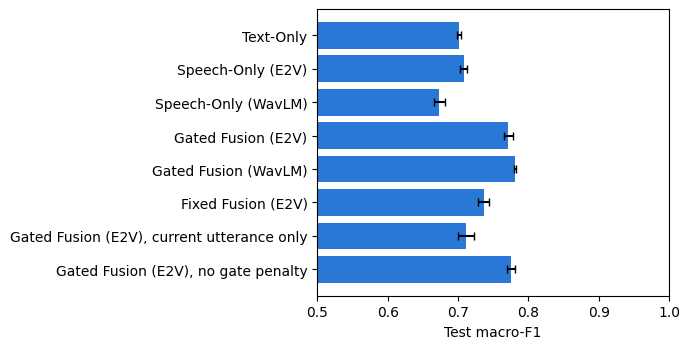

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

from dataset import CLASS_NAMES

FIG_DIR = os.path.join(OUTPUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# Macro-F1 per setting (mean and std across seeds)
fig, ax = plt.subplots(figsize=(7, 3.6))
y = np.arange(len(summary))[::-1]
ax.barh(y, summary['test_macro_f1_mean'], xerr=summary['test_macro_f1_std'], color='#2a78d6', capsize=3)
ax.set_yticks(y)
ax.set_yticklabels(summary.index)
ax.set_xlabel('Test macro-F1')
lo = (summary['test_macro_f1_mean'] - summary['test_macro_f1_std'].fillna(0)).min()
ax.set_xlim(max(0, np.floor(lo * 10) / 10 - 0.1), 1)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'macro_f1.png'), dpi=200)
plt.show()

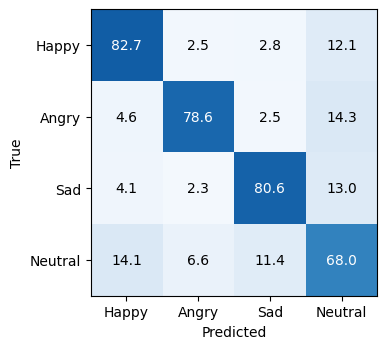

In [10]:
# Confusion matrix of gated fusion (E2V), all folds and seeds pooled, rows normalised
p = preds[preds['setting'] == 'Gated Fusion (E2V)']
cm = confusion_matrix(p['label'], p['pred'], normalize='true') * 100
fig, ax = plt.subplots(figsize=(4, 3.6))
ax.imshow(cm, cmap='Blues', vmin=0, vmax=100)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f'{cm[i, j]:.1f}', ha='center', va='center', color='white' if cm[i, j] > 60 else 'black')
ax.set_xticks(range(4))
ax.set_xticklabels(CLASS_NAMES)
ax.set_yticks(range(4))
ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'confusion_gated_e2v.png'), dpi=200)
plt.show()

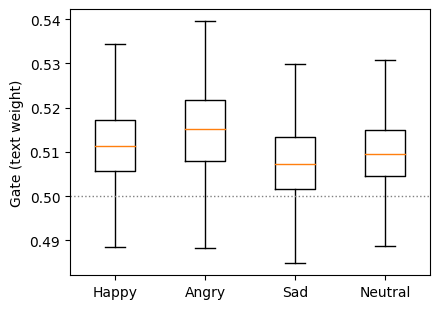

gate_target                                                   \
            count   mean    std    min    25%    50%    75%    max   
label                                                                
0          4908.0  0.512  0.008  0.482  0.506  0.511  0.517  0.538   
1          3309.0  0.515  0.009  0.486  0.508  0.515  0.522  0.540   
2          3252.0  0.508  0.008  0.482  0.502  0.507  0.513  0.536   
3          5124.0  0.510  0.008  0.482  0.505  0.510  0.515  0.542   

      gate_dim_std         ...               gate_time_std                \
             count   mean  ...    75%    max         count   mean    std   
label                      ...                                             
0           4908.0  0.180  ...  0.192  0.258        4818.0  0.133  0.017   
1           3309.0  0.187  ...  0.202  0.276        3282.0  0.132  0.019   
2           3252.0  0.186  ...  0.202  0.271        3210.0  0.130  0.018   
3           5124.0  0.175  ...  0.185  0.248        4998.0  0.138  0.016   

                                          
         min    25%    50%    75%    max  
label                                     
0      0.051  0.123  0.133  0.143  0.213  
1      0.068  0.119  0.132  0.144  0.191  
2      0.067  0.118  0.130  0.142  0.225  
3      0.074  0.127  0.138  0.148  0.205  

[4 rows x 24 columns]

In [11]:
# Text weight of the gate at the target utterance, by true emotion (gated fusion, E2V)
fig, ax = plt.subplots(figsize=(4.5, 3.2))
ax.boxplot([p.loc[p['label'] == k, 'gate_target'] for k in range(4)], showfliers=False)
ax.set_xticks(range(1, 5))
ax.set_xticklabels(CLASS_NAMES)
ax.axhline(0.5, color='grey', linestyle=':', linewidth=1)
ax.set_ylabel('Gate (text weight)')
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'gate_by_emotion.png'), dpi=200)
plt.show()
p.groupby('label')[['gate_target', 'gate_dim_std', 'gate_time_std']].describe().round(3)